In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [2]:
df = pd.read_csv('laptopData(Target column Price).csv')

In [3]:
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,NaN,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,NaN,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,NaN,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [5]:
df.shape

(1303, 12)

In [6]:
df.isnull().sum().sort_values(ascending=False)

Cpu                 233
Ram                 215
Memory              199
ScreenResolution    185
Gpu                 154
Inches              120
TypeName            120
OpSys               110
Weight              101
Price                68
Company              65
Unnamed: 0           57
dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1246 non-null   float64
 1   Company           1238 non-null   str    
 2   TypeName          1183 non-null   str    
 3   Inches            1183 non-null   float64
 4   ScreenResolution  1118 non-null   str    
 5   Cpu               1070 non-null   str    
 6   Ram               1088 non-null   str    
 7   Memory            1104 non-null   str    
 8   Gpu               1149 non-null   str    
 9   OpSys             1193 non-null   str    
 10  Weight            1202 non-null   str    
 11  Price             1235 non-null   float64
dtypes: float64(3), str(9)
memory usage: 122.3 KB


In [9]:
df.describe()

,Unnamed: 0,Inches,Price
count,1246.000000,1183.000000,1235.000000
mean,660.506421,15.097380,59854.550097
std,376.558891,1.859457,37126.926121
min,0.000000,10.100000,9270.720000
25%,341.250000,14.000000,31914.720000
50%,666.000000,15.600000,52161.120000
75%,986.750000,15.600000,79274.246400
max,1302.000000,35.600000,324954.720000


In [10]:
df = df.dropna(subset=['Price'])

In [11]:
df.isnull().sum().sort_values(ascending=False)

Cpu                 165
Ram                 147
Memory              131
ScreenResolution    127
Gpu                  86
Inches               62
TypeName             62
OpSys                42
Weight               33
Company               7
Unnamed: 0            7
Price                 0
dtype: int64

In [12]:
df.drop('Unnamed: 0', axis=1, inplace=True)

In [13]:
df.dtypes

Company                 str
TypeName                str
Inches              float64
ScreenResolution        str
Cpu                     str
Ram                     str
Memory                  str
Gpu                     str
OpSys                   str
Weight                  str
Price               float64
dtype: object

In [ ]:
df['Ram'] = df['Ram'].astype(str)
df['Weight'] = df['Weight'].astype(str)

df['Ram'] = df['Ram'].replace('?', np.nan)
df['Weight'] = df['Weight'].replace('?', np.nan)

df['Ram'] = df['Ram'].str.replace('GB', '', regex=False)
df['Weight'] = df['Weight'].str.replace('kg', '', regex=False)

df['Ram'] = pd.to_numeric(df['Ram'], errors='coerce')
df['Weight'] = pd.to_numeric(df['Weight'], errors='coerce')

In [17]:
numerical_cols = ['Inches', 'Ram', 'Weight']

categorical_cols = [
    'Company', 'TypeName', 'ScreenResolution',
    'Cpu', 'Memory', 'Gpu', 'OpSys'
]

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [18]:
df.isnull().sum()

Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

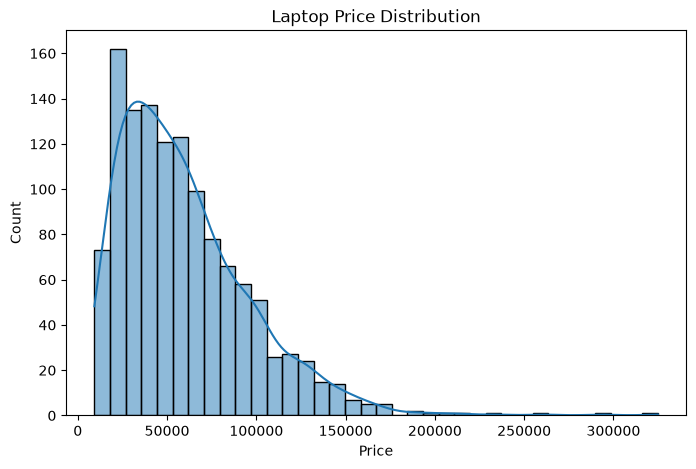

In [19]:
plt.figure(figsize=(8,5))
sns.histplot(df['Price'], kde=True)
plt.title('Laptop Price Distribution')
plt.show()

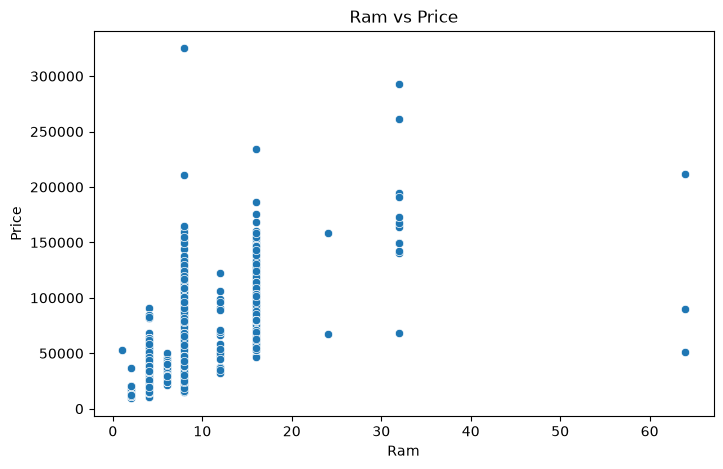

In [20]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Ram', y='Price')
plt.title('Ram vs Price')
plt.show()

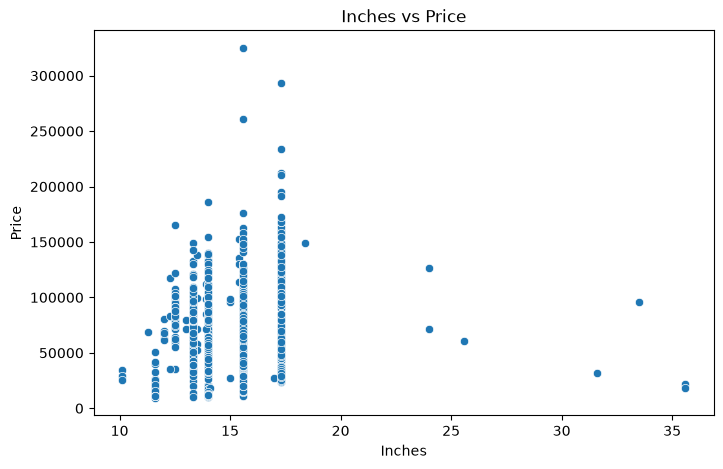

In [21]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Inches', y='Price')
plt.title('Inches vs Price')
plt.show()

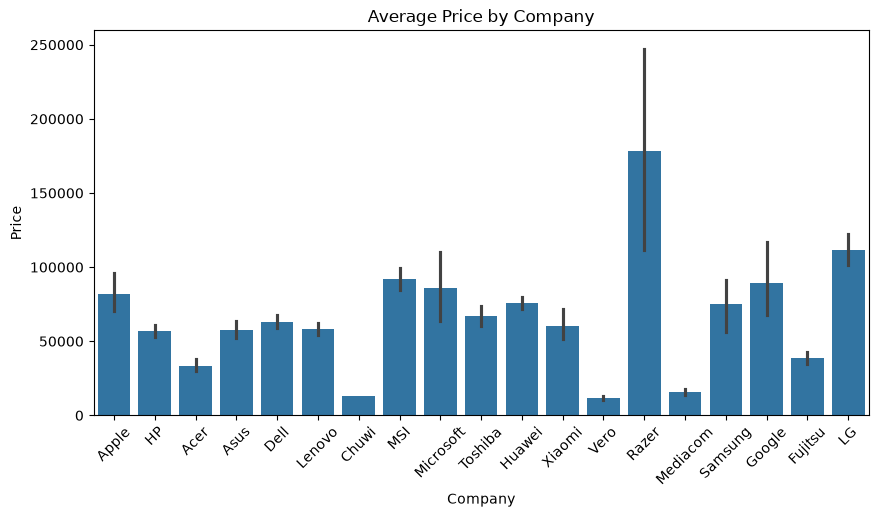

In [22]:
plt.figure(figsize=(10,5))
sns.barplot(data=df, x='Company', y='Price')
plt.xticks(rotation=45)
plt.title('Average Price by Company')
plt.show()

In [23]:
X = df.drop('Price', axis=1)
y = df['Price']

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [26]:
numerical_cols = X.select_dtypes(include=np.number).columns

categorical_cols = X.select_dtypes(exclude=np.number).columns

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

In [28]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [32]:
from scipy.sparse import issparse

if issparse(X_train_processed):
    X_train_processed = X_train_processed.toarray()

if issparse(X_test_processed):
    X_test_processed = X_test_processed.toarray()

In [33]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [34]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

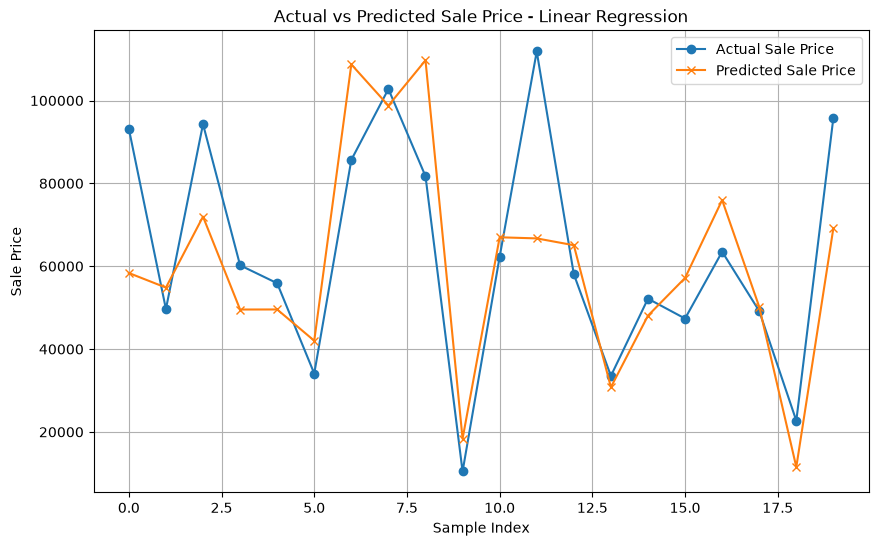

  7%|▋         | 1/15 [00:00<00:10,  1.30it/s]

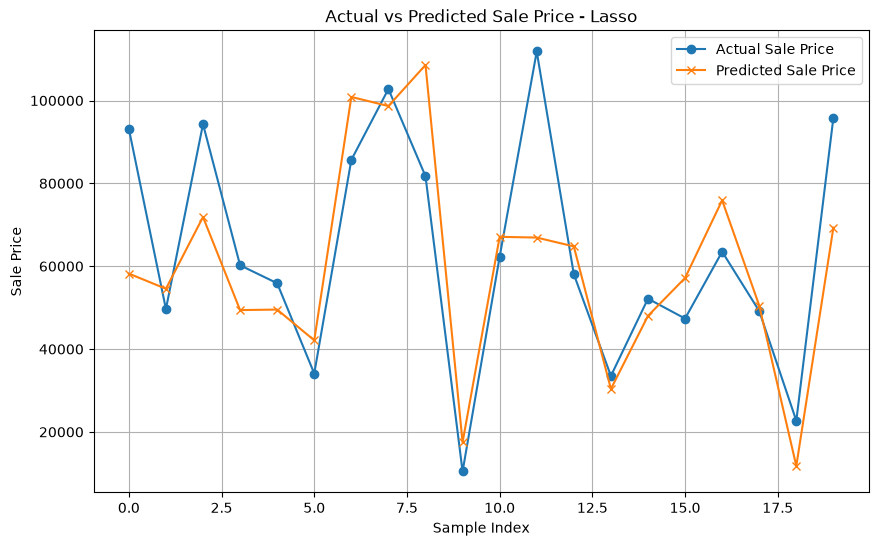

 13%|█▎        | 2/15 [00:00<00:05,  2.30it/s]

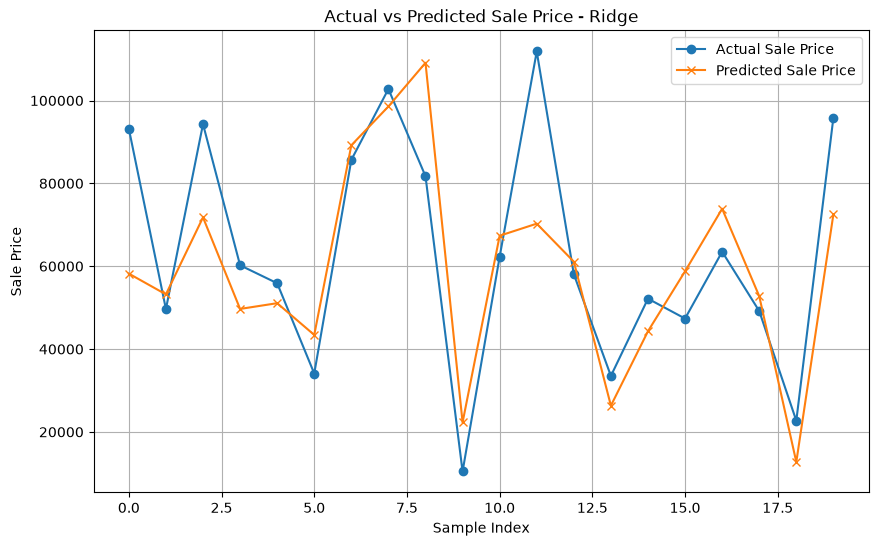

 20%|██        | 3/15 [00:01<00:04,  2.59it/s]

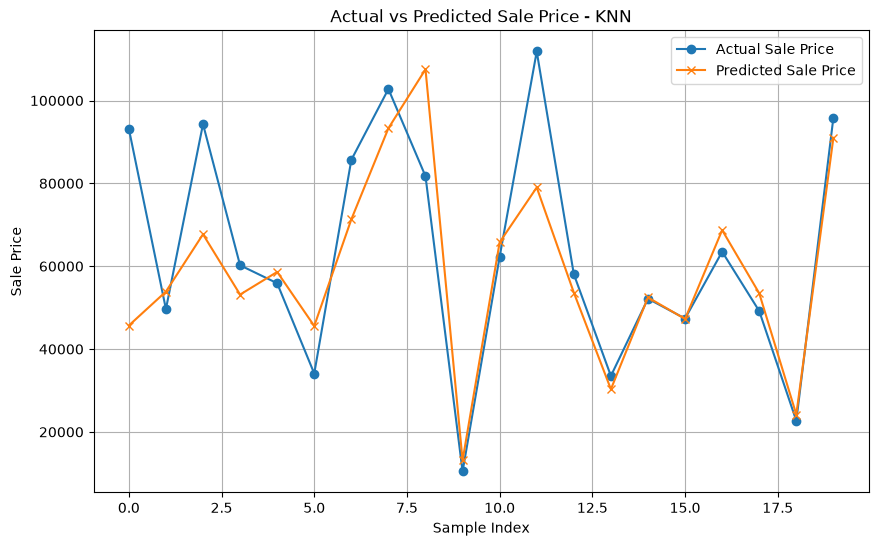

 27%|██▋       | 4/15 [00:01<00:03,  3.21it/s]

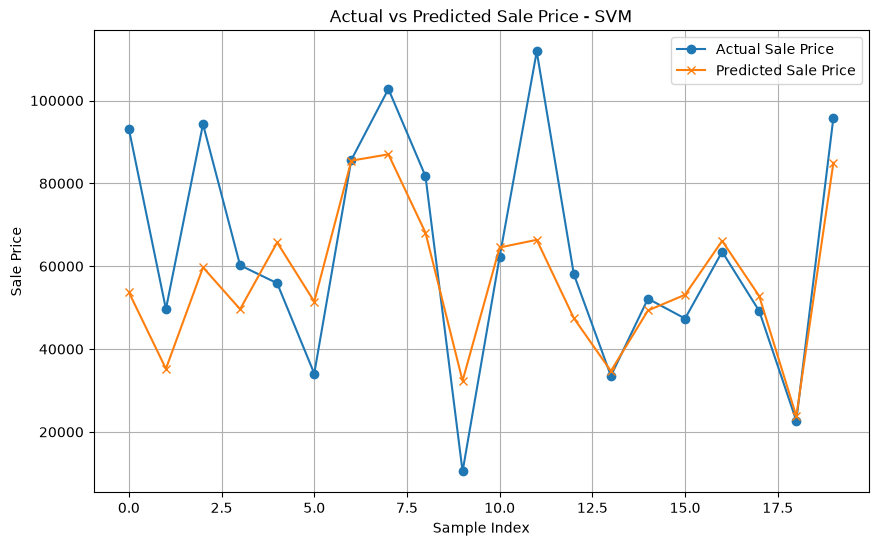

 33%|███▎      | 5/15 [00:01<00:02,  3.39it/s]

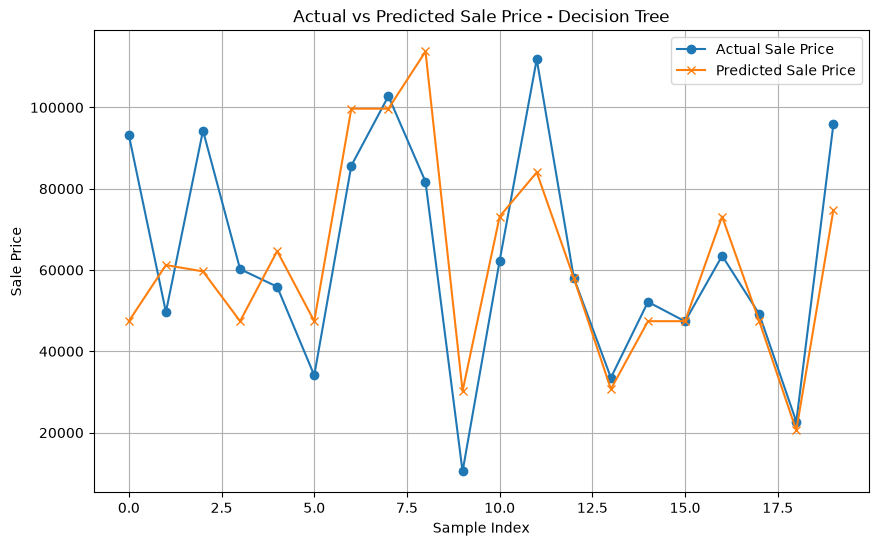

 40%|████      | 6/15 [00:01<00:02,  4.04it/s]

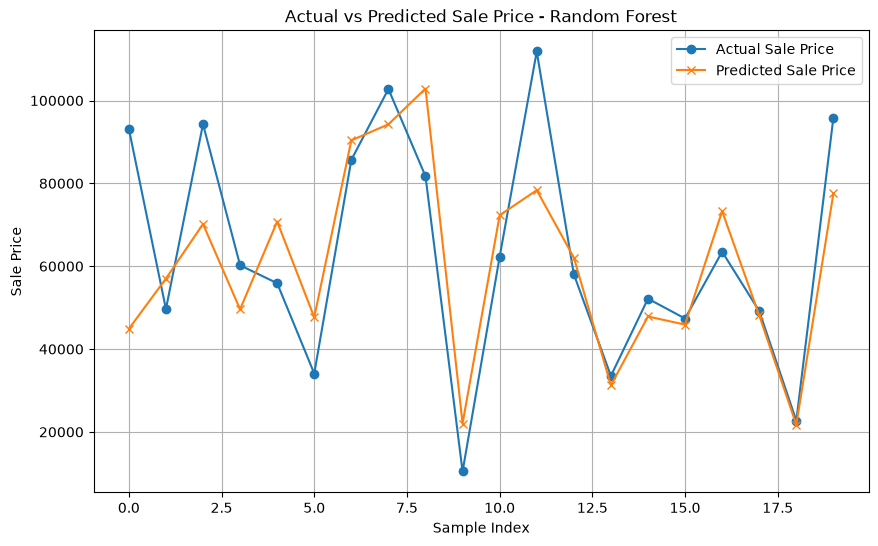

 47%|████▋     | 7/15 [00:02<00:02,  3.28it/s]

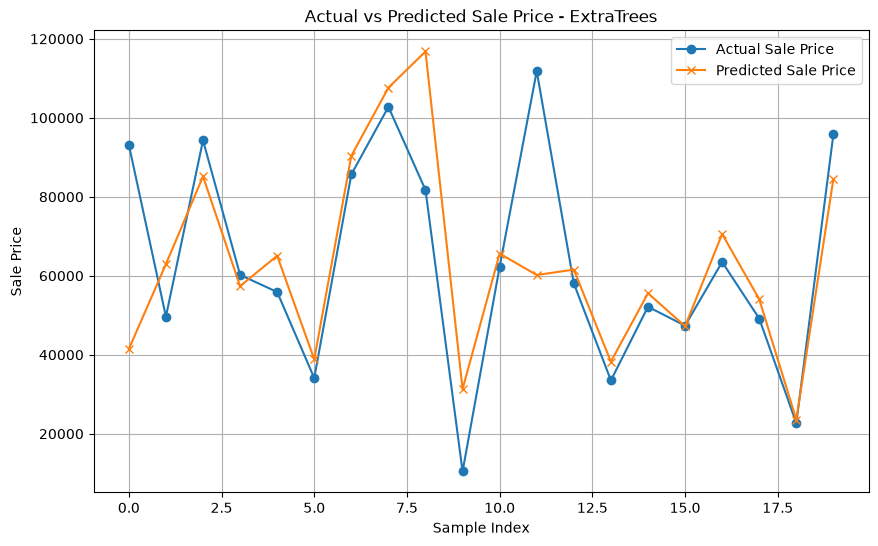

 53%|█████▎    | 8/15 [00:03<00:04,  1.47it/s]

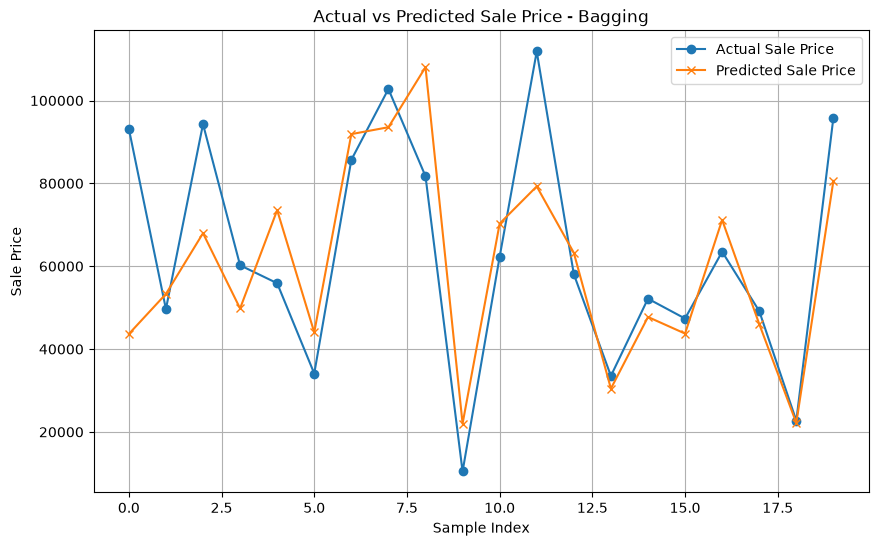

 60%|██████    | 9/15 [00:04<00:03,  1.50it/s]

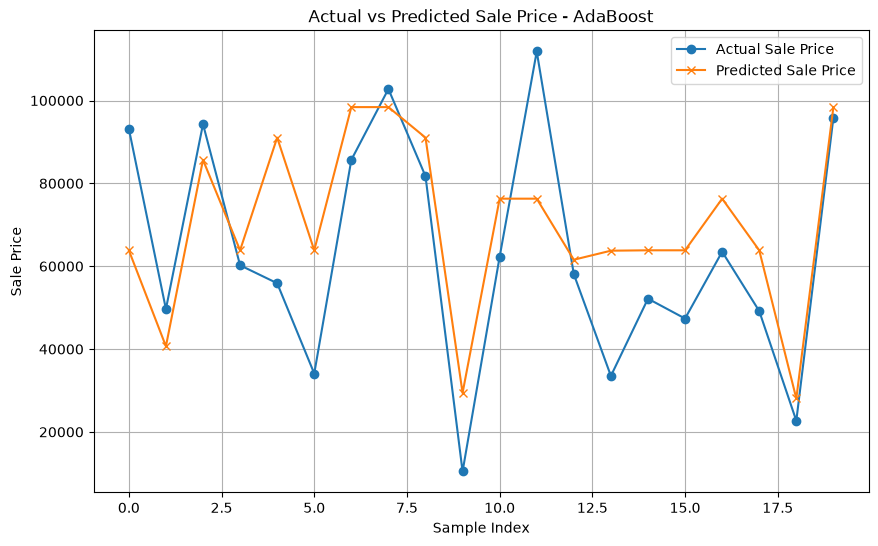

 67%|██████▋   | 10/15 [00:04<00:02,  1.88it/s]

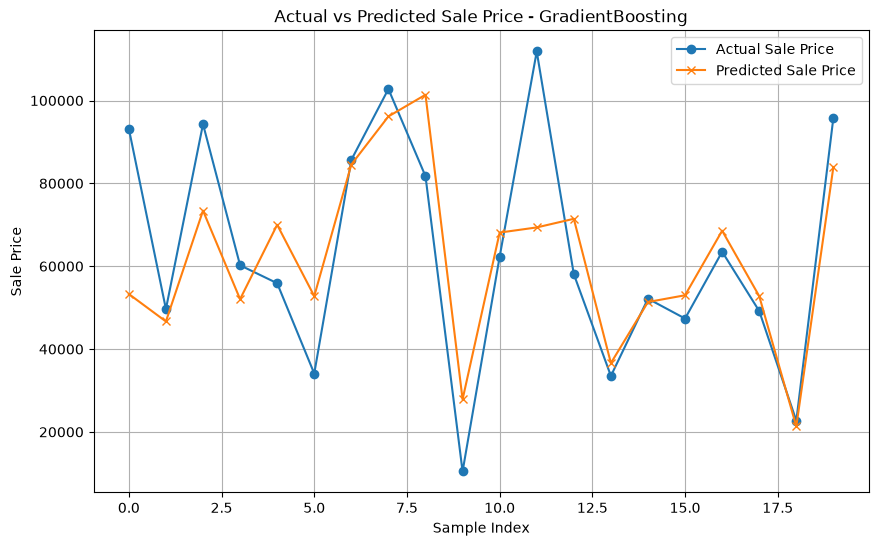

 73%|███████▎  | 11/15 [00:05<00:02,  1.89it/s]

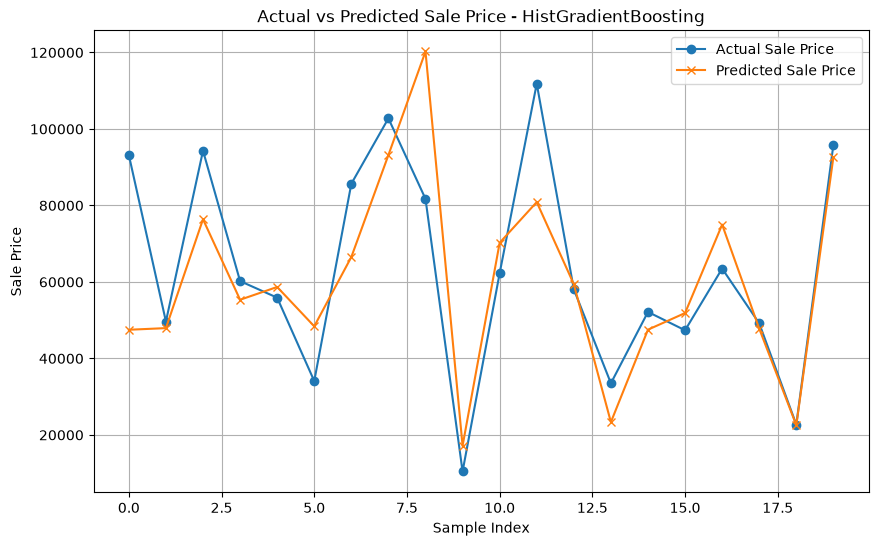

 80%|████████  | 12/15 [00:06<00:02,  1.18it/s]

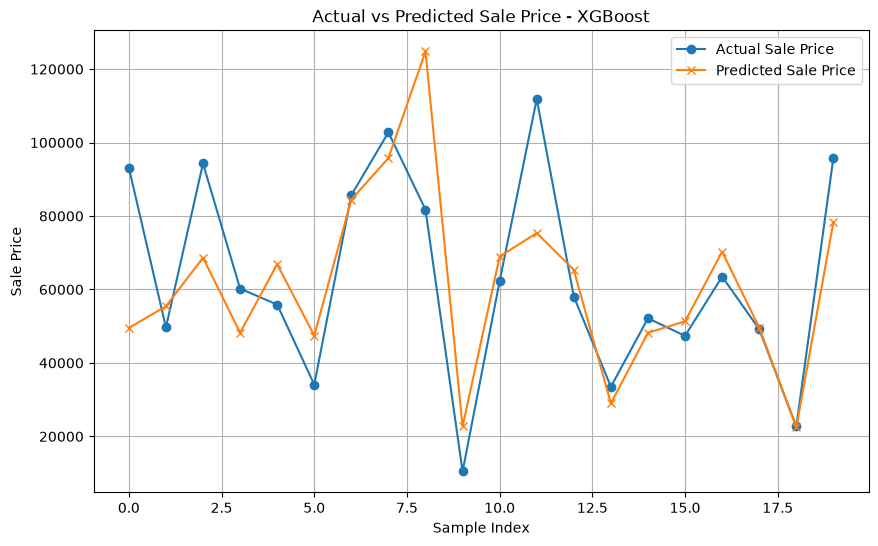

 87%|████████▋ | 13/15 [00:07<00:01,  1.49it/s]

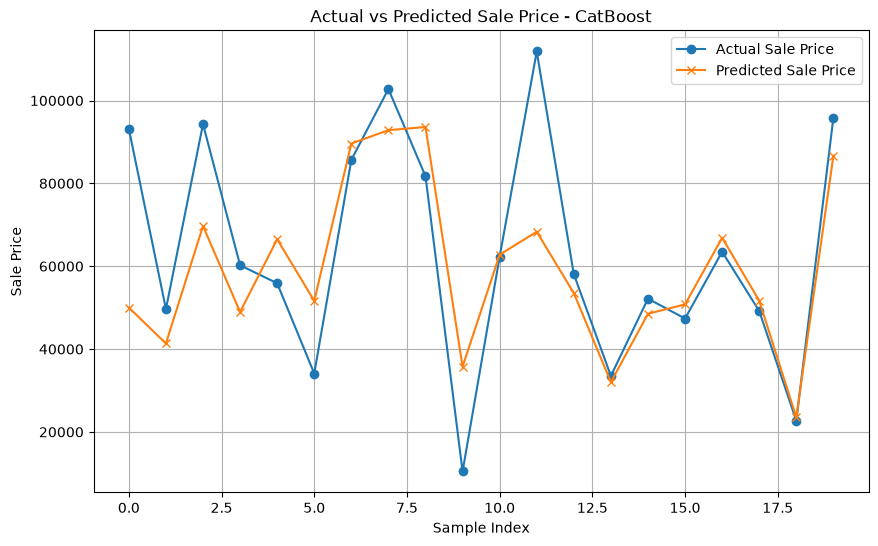

 93%|█████████▎| 14/15 [00:07<00:00,  1.65it/s]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000282 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 241
[LightGBM] [Info] Number of data points in the train set: 988, number of used features: 55
[LightGBM] [Info] Start training from score 59838.542462


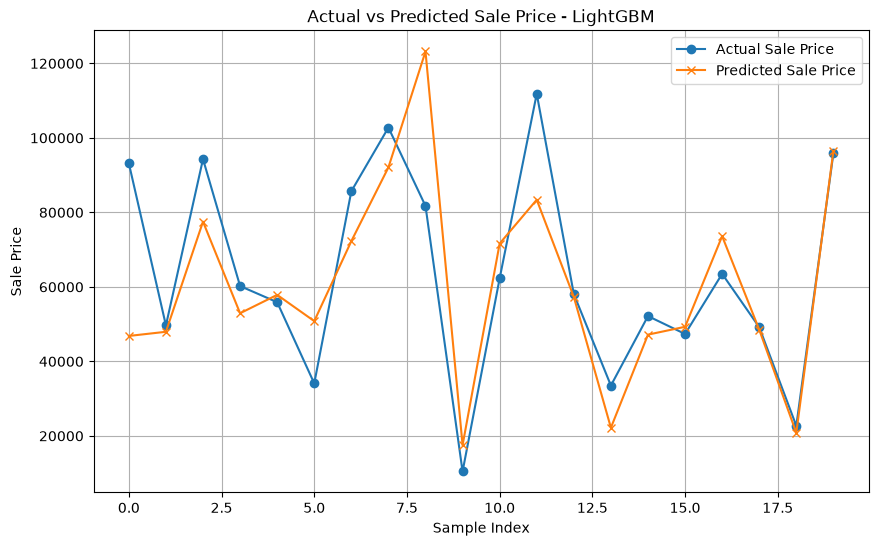

100%|██████████| 15/15 [00:07<00:00,  1.95it/s]


In [35]:

errors = {}

for model_name, model in tqdm(models.items()):

    # Training
    model.fit(X_train_processed, y_train)

    # Train Metrics
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(
        model, X_train_processed, y_train
    )

    # Test Metrics
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(
        model, X_test_processed, y_test
    )

    # Save Results
    errors[model_name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R_Train,
        "R2 Test": R_Test
    }

    # Actual vs Predicted (First 20 Samples)
    y_test_plot = y_test.iloc[:20].values
    y_pred_plot = model.predict(X_test_processed[:20])

    plt.figure(figsize=(10, 6))

    plt.plot(range(20), y_test_plot,
             label='Actual Sale Price', marker='o')

    plt.plot(range(20), y_pred_plot,
             label='Predicted Sale Price', marker='x')

    plt.xlabel('Sample Index')
    plt.ylabel('Sale Price')
    plt.title('Actual vs Predicted Sale Price - ' + model_name)

    plt.legend()
    plt.grid()
    plt.show()


In [36]:
results_df = pd.DataFrame(errors).T
display(results_df)

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Linear Regression,8745.232580,13881.706616,1.744990e+08,4.401969e+08,13209.805771,20980.868938,0.871631,0.696212
Lasso,8871.564202,13832.805937,1.747460e+08,4.595976e+08,13219.153723,21438.227684,0.871450,0.682823
Ridge,10025.084005,13284.252589,2.072590e+08,3.960563e+08,14396.493228,19901.162665,0.847532,0.726674
KNN,9820.776896,11997.864350,2.661986e+08,3.793843e+08,16315.592611,19477.790235,0.804173,0.738180
SVM,16339.755387,16133.765757,6.734960e+08,6.177477e+08,25951.800713,24854.529786,0.504548,0.573681
Decision Tree,8415.668437,15152.209712,1.715172e+08,6.076306e+08,13096.458107,24650.163732,0.873825,0.580663
Random Forest,8664.764201,12252.107444,1.604752e+08,4.020019e+08,12667.880437,20049.985954,0.881948,0.722571
ExtraTrees,206.515006,12172.596908,1.229821e+06,4.202127e+08,1108.972836,20499.090504,0.999095,0.710004
Bagging,8509.980646,12353.181786,1.474935e+08,4.110072e+08,12144.689467,20273.312634,0.891498,0.716357
AdaBoost,17901.622521,17822.335522,5.205552e+08,6.230858e+08,22815.678974,24961.686881,0.617058,0.569997
